In [1]:
import os 
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt 

matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [2]:
data_path = '/home/ruppk2@hhmi.org/tracktail-paper/data/v2/dexycb_ncam_results.csv'
outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v2'
data = pd.read_csv(data_path)


In [3]:
# metric column name -> display label
metrics_dict = {
'mte':                'MTE',
'delta_x_avg': r'$\delta_{avg}$',
'occlusion_acc': 'Occlusion Accuracy',
'avg_jaccard':        'Avg Jaccard (AJ)',
'mpjpe':              'MPJPE',
# 'survival_rate':      'Survival Rate',
}

method_dict = {'CoTracker3 Baseline': 'CoTracker3 Baseline', 
               'MVTracker Baseline': 'MVTracker Baseline (DUST3R)', 
               'Tracktail': 'Tracktail'}

dataset_dict = {'cmupanoptic_3dgs': 'CMUPanoptic 3DGS',
                'dex_ycb': 'Dex YCB',
                'kubric-multiview': 'Kubric Multiview'}


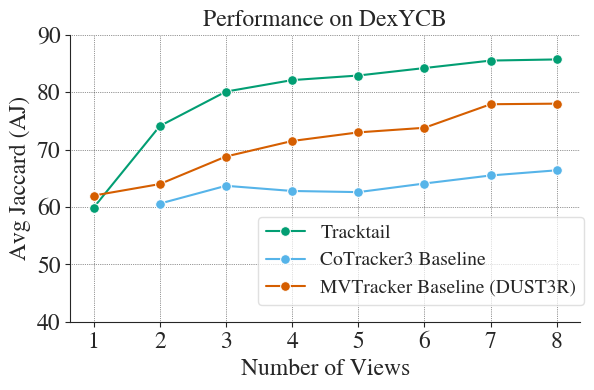

In [7]:

# sns.set_style('ticks')
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
df = data.melt(id_vars='n_views', var_name='method', value_name='avg_jaccard')
method_order = ['Tracktail', 'CoTracker3 Baseline', 'MVTracker Baseline']
df['method'] = pd.Categorical(df['method'], categories=method_order, ordered=True)
df = df.sort_values('method')

fs = 17

metric = 'avg_jaccard'
fig, ax = plt.subplots(1, 1, figsize = (6, 4), sharey = False)

# palette = sns.color_palette('rainbow', n_colors = 6)
# colors = [palette[0], palette[5], palette[1]]
palette = sns.color_palette('colorblind', n_colors = 12)
colors = [palette[2], palette[9], palette[3]]
# colors = [palette[4], palette[9], palette[3]]


sns.lineplot(
    data=df,
    x='n_views',
    y='avg_jaccard',
    hue='method',
    marker='o',
    markersize = 7,
    palette=colors,
    ax=ax,
)

# ax.set_title(metrics_dict[metric], fontsize = fs)
ax.set_xlabel('Number of Views', fontsize = fs)
ax.set_ylabel(metrics_dict[metric], fontsize = fs)
ax.set_title('Performance on DexYCB', fontsize = fs)
ax.set_xticks(sorted(df['n_views'].unique()))
ax.tick_params(axis = 'x', labelsize = fs)
ax.tick_params(axis = 'y', labelsize = fs)
ax.get_legend().remove()
ax.grid(True, linestyle=':', color = 'k', linewidth=0.5, alpha=0.8)
ax.set_ylim([40, 90])

# single shared legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
labels = [method_dict[method] for method in labels]
fig.legend(handles, labels, 
           loc='upper center',
           bbox_to_anchor = (0.71, 0.47), 
           framealpha = 0.7, 
           facecolor = 'white', 
           edgecolor = 'lightgray',
           fontsize = fs - 3)

plt.tight_layout()
sns.despine() 

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)
    
fig.savefig(os.path.join(outpath, 'n_cams_figure.pdf'), dpi=800, bbox_inches='tight')